In [17]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow import keras
from tensorflow.keras import layers

from sklearn.model_selection import train_test_split
from sklearn.datasets import load_diabetes
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

In [18]:
# Reproducibility
keras.utils.set_random_seed(42)

In [19]:
# 1. Load the regression dataset
dataset_reg = load_diabetes()
X_reg = dataset_reg.data.astype("float32")
y_reg = dataset_reg.target.astype("float32")

print("Regression feature shape:", X_reg.shape)
print("Regression target shape:", y_reg.shape)

Regression feature shape: (442, 10)
Regression target shape: (442,)


In [20]:
# 2. Split the data
Xr_trainval, Xr_test, yr_trainval, yr_test = train_test_split(
    X_reg, y_reg,
    test_size=0.20,
    random_state=42
)

Xr_train, Xr_val, yr_train, yr_val = train_test_split(
    Xr_trainval, yr_trainval,
    test_size=0.20,
    random_state=42
)

print("Train:", Xr_train.shape)
print("Validation:", Xr_val.shape)
print("Test:", Xr_test.shape)

Train: (282, 10)
Validation: (71, 10)
Test: (89, 10)


In [21]:
# 3. Build a regression model
def build_regressor(input_dim, architecture):
    normalizer = layers.Normalization()
    normalizer.adapt(Xr_train)

    model = keras.Sequential([
        keras.Input(shape=(input_dim,)),
        normalizer
    ])

    if architecture == "small":
        model.add(layers.Dense(16, activation="relu"))
    elif architecture == "larger":
        model.add(layers.Dense(64, activation="relu"))
        model.add(layers.Dense(32, activation="relu"))

    # Linear output for unrestricted numeric prediction
    model.add(layers.Dense(1))

    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=0.001),
        loss="mse",
        metrics=["mae"]
    )

    return model


In [22]:
# 4. Train and compare both architectures
regression_results = {}
regression_histories = {}
regression_models = {}

for architecture in ["small", "larger"]:
    keras.utils.set_random_seed(42)

    model = build_regressor(Xr_train.shape[1], architecture)

    history = model.fit(
        Xr_train, yr_train,
        validation_data=(Xr_val, yr_val),
        epochs=100,
        batch_size=32,
        callbacks=[
            keras.callbacks.EarlyStopping(
                monitor="val_loss",
                patience=10,
                restore_best_weights=True
            )
        ],
        verbose=0
    )

    predictions = model.predict(Xr_test, verbose=0).ravel()

    mae = mean_absolute_error(yr_test, predictions)
    mse = mean_squared_error(yr_test, predictions)
    rmse = np.sqrt(mse)
    r2 = r2_score(yr_test, predictions)

    regression_results[architecture] = {
        "MAE": mae,
        "MSE": mse,
        "RMSE": rmse,
        "R2": r2
    }

    regression_models[architecture] = model
    regression_histories[architecture] = history

    print(f"\nArchitecture: {architecture}")
    print(regression_results[architecture])


2026-10-22 18:06:55.083511: I tensorflow/core/grappler/optimizers/custom_graph_optimizer_registry.cc:114] Plugin optimizer for device_type GPU is enabled.
2026-10-22 18:06:55.126324: I tensorflow/core/grappler/optimizers/custom_graph_optimizer_registry.cc:114] Plugin optimizer for device_type GPU is enabled.
2026-10-22 18:06:55.692002: I tensorflow/core/grappler/optimizers/custom_graph_optimizer_registry.cc:114] Plugin optimizer for device_type GPU is enabled.
2026-10-22 18:06:55.748195: I tensorflow/core/common_runtime/pluggable_device/pluggable_device_factory.cc:306] Could not identify NUMA node of platform GPU ID 0, defaulting to 0. Your kernel may not have been built with NUMA support.
2026-10-22 18:06:55.748306: I tensorflow/core/common_runtime/pluggable_device/pluggable_device_factory.cc:272] Created TensorFlow device (/job:localhost/replica:0/task:0/device:GPU:0 with 6941 MB memory) -> physical PluggableDevice (device: 0, name: DML, pci bus id: <undefined>)
2026-10-22 18:06:56.0


Architecture: small
{'MAE': 100.05623626708984, 'MSE': 13563.49609375, 'RMSE': 116.46242352686123, 'R2': -1.5600428581237793}


2026-10-22 18:07:12.464593: I tensorflow/core/grappler/optimizers/custom_graph_optimizer_registry.cc:114] Plugin optimizer for device_type GPU is enabled.
2026-10-22 18:07:12.860838: I tensorflow/core/grappler/optimizers/custom_graph_optimizer_registry.cc:114] Plugin optimizer for device_type GPU is enabled.
2026-10-22 18:07:12.903043: I tensorflow/core/common_runtime/pluggable_device/pluggable_device_factory.cc:306] Could not identify NUMA node of platform GPU ID 0, defaulting to 0. Your kernel may not have been built with NUMA support.
2026-10-22 18:07:12.903112: I tensorflow/core/common_runtime/pluggable_device/pluggable_device_factory.cc:272] Created TensorFlow device (/job:localhost/replica:0/task:0/device:GPU:0 with 6941 MB memory) -> physical PluggableDevice (device: 0, name: DML, pci bus id: <undefined>)
2026-10-22 18:07:13.090669: I tensorflow/core/grappler/optimizers/custom_graph_optimizer_registry.cc:114] Plugin optimizer for device_type GPU is enabled.
2026-10-22 18:07:13.1


Architecture: larger
{'MAE': 44.50393295288086, 'MSE': 3015.2109375, 'RMSE': 54.91093641070056, 'R2': 0.43089383840560913}


2026-10-22 18:07:27.445248: I tensorflow/core/grappler/optimizers/custom_graph_optimizer_registry.cc:114] Plugin optimizer for device_type GPU is enabled.
2026-10-22 18:07:27.471325: I tensorflow/core/common_runtime/pluggable_device/pluggable_device_factory.cc:306] Could not identify NUMA node of platform GPU ID 0, defaulting to 0. Your kernel may not have been built with NUMA support.
2026-10-22 18:07:27.471404: I tensorflow/core/common_runtime/pluggable_device/pluggable_device_factory.cc:272] Created TensorFlow device (/job:localhost/replica:0/task:0/device:GPU:0 with 6941 MB memory) -> physical PluggableDevice (device: 0, name: DML, pci bus id: <undefined>)
2026-10-22 18:07:27.476320: I tensorflow/core/common_runtime/pluggable_device/pluggable_device_factory.cc:306] Could not identify NUMA node of platform GPU ID 0, defaulting to 0. Your kernel may not have been built with NUMA support.
2026-10-22 18:07:27.476409: I tensorflow/core/common_runtime/pluggable_device/pluggable_device_fa

In [23]:
history = regression_histories["small"]

best_epoch = np.argmin(history.history["val_loss"]) + 1

print("Best validation-loss epoch:", best_epoch)
print("Best validation loss:", min(history.history["val_loss"]))

Best validation-loss epoch: 100
Best validation loss: 17968.5625


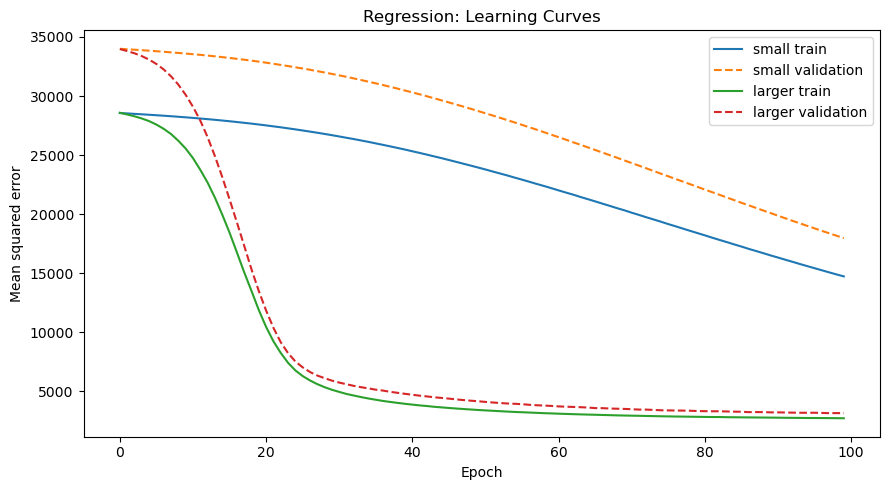

In [24]:
# 5. Compare training and validation loss
plt.figure(figsize=(9, 5))

for architecture, history in regression_histories.items():
    plt.plot(
        history.history["loss"],
        label=f"{architecture} train"
    )
    plt.plot(
        history.history["val_loss"],
        linestyle="--",
        label=f"{architecture} validation"
    )

plt.xlabel("Epoch")
plt.ylabel("Mean squared error")
plt.title("Regression: Learning Curves")
plt.legend()
plt.tight_layout()
plt.show()

2026-10-22 18:07:27.903089: I tensorflow/core/grappler/optimizers/custom_graph_optimizer_registry.cc:114] Plugin optimizer for device_type GPU is enabled.


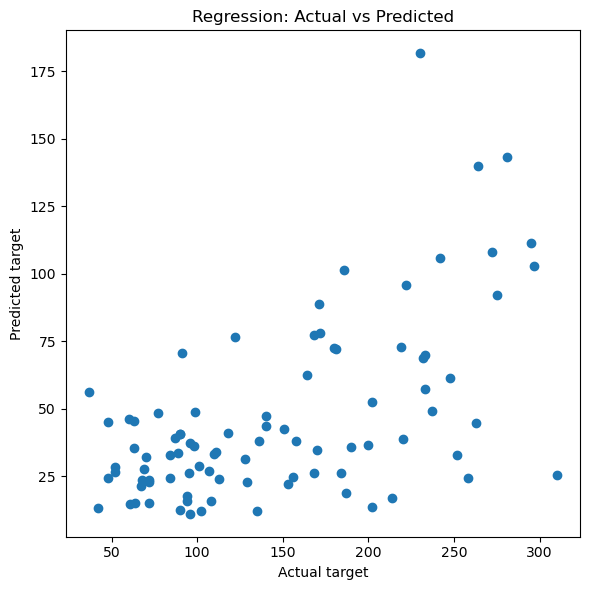

In [25]:
# 6. Compare actual and predicted values for one model
chosen_model = regression_models["small"]
predictions = chosen_model.predict(Xr_test, verbose=0).ravel()

plt.figure(figsize=(6, 6))
plt.scatter(yr_test, predictions)
plt.xlabel("Actual target")
plt.ylabel("Predicted target")
plt.title("Regression: Actual vs Predicted")
plt.tight_layout()
plt.show()